# Mini-Project 2 — Solar Micro-Grid Dispatch Planner (Kasese health centre)

**Scenario.** Each day, solar energy *x* and battery energy *y* (kWh) must satisfy

$$3x + 2y = D_1 \quad\text{(daytime load)}, \qquad 4x + y = D_2 \quad\text{(critical-equipment load)}$$

**Assumptions.** The coefficients are given by the brief; demands are in kWh/day; tariffs are UGX 150/kWh (solar) and UGX 450/kWh (battery), both illustrative. The 30-day demand file is **synthetic** (seeded) and described below.

Logic lives in `src/microgrid.py`: `MicroGrid` (2×2) and its subclass `HybridMicroGrid` (3×3 with diesel).

In [1]:
import timeit
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.microgrid import (HybridMicroGrid, MicroGrid, generate_demand_csv, load_demand_csv,
                           prompt_demand, sensitivity_monte_carlo)

SEED = 2026
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Is the system well-posed?

In [2]:
grid = MicroGrid()
print(grid)
print("A =\n", grid.A)
print(f"det(A) = {grid.determinant:.3f}")
print(f"cond(A) = {grid.condition_number:.3f}   (exact: 3 + 2√2 = {3 + 2 * np.sqrt(2):.3f})")
print("Well-posed:", grid.is_well_posed())

MicroGrid(sources=('solar', 'battery'), det=-5)
A =
 [[3. 2.]
 [4. 1.]]
det(A) = -5.000
cond(A) = 5.828   (exact: 3 + 2√2 = 5.828)
Well-posed: True


**Determinant = −5.** A non-zero determinant means the two load equations are independent, so each day has **exactly one** solution. Solving by hand: x = (2D₂ − D₁)/5 and y = (4D₁ − 3D₂)/5. The sign has no physical meaning; it only reflects row orientation.

**Condition number ≈ 5.83** (2-norm: ratio of the largest to smallest singular value). It bounds how much a *relative* error in the demands can be amplified in the solution: ‖Δs‖/‖s‖ ≤ 5.83 · ‖Δd‖/‖d‖. A 1% metering error can therefore move the dispatch by up to about 6%. That is well-conditioned (we lose under one significant digit; trouble starts around 10⁶+), but not negligible for planning, as the sensitivity analysis below confirms.

**Feasibility band.** x ≥ 0 requires D₂ ≥ D₁/2, and y ≥ 0 requires D₂ ≤ (4/3)·D₁. Any day whose critical load exceeds 133% of the daytime load is physically impossible to meet with these two sources.

## 2. Two input modes
**(a) Interactive.** `prompt_demand` re-prompts on empty, non-numeric, negative or non-finite input. Its `input` function is injectable, so the notebook can demonstrate it without blocking *Restart & Run All*. Set `INTERACTIVE = True` to type values yourself.

In [3]:
INTERACTIVE = False

if INTERACTIVE:
    d1 = prompt_demand("Daytime load D1 (kWh): ")
    d2 = prompt_demand("Critical load D2 (kWh): ")
else:
    scripted = iter(["", "lots", "-40", "100",      # three bad attempts, then a valid D1
                     "110"])                         # valid D2
    def fake_input(prompt):
        value = next(scripted)
        print(f"{prompt}{value!r}")
        return value
    d1 = prompt_demand("Daytime load D1 (kWh): ", input_fn=fake_input)
    d2 = prompt_demand("Critical load D2 (kWh): ", input_fn=fake_input)

x, y = grid.solve_day(d1, d2)
print(f"\nD1={d1}, D2={d2} → solar x = {x:.2f} kWh, battery y = {y:.2f} kWh   (hand: 24, 14)")

Daytime load D1 (kWh): ''
  Invalid input: value is empty. Please try again.
Daytime load D1 (kWh): 'lots'
  Invalid input: 'lots' is not a number. Please try again.
Daytime load D1 (kWh): '-40'
  Invalid input: demand cannot be negative. Please try again.
Daytime load D1 (kWh): '100'
Critical load D2 (kWh): '110'

D1=100.0, D2=110.0 → solar x = 24.00 kWh, battery y = 14.00 kWh   (hand: 24, 14)


**(b) CSV.** 30 days of synthetic demand. **Generating model:** weekday daytime load ≈ 120 kWh (outpatient clinics running), weekend ≈ 95 kWh, plus Gaussian noise (SD 8). Critical load ≈ 1.05 × daytime load plus independent noise (SD 18), standing for vaccine fridges, oxygen and lab equipment that do not track footfall exactly. The independent noise means some days break the feasibility band, which tests task 4.

In [4]:
generate_demand_csv("data/kasese_demand.csv", days=30, seed=SEED)
demand = load_demand_csv("data/kasese_demand.csv")
demand_df = pd.DataFrame(demand, columns=["D1 (kWh)", "D2 (kWh)"], index=pd.RangeIndex(1, 31, name="day"))
demand_df["D2/D1"] = demand_df["D2 (kWh)"] / demand_df["D1 (kWh)"]
display(demand_df.head(10))
print("Weekday mean D1:", demand_df["D1 (kWh)"][(demand_df.index - 1) % 7 < 5].mean().round(1),
      "| weekend mean D1:", demand_df["D1 (kWh)"][(demand_df.index - 1) % 7 >= 5].mean().round(1))

,D1 (kWh),D2 (kWh),D2/D1
day,,,
1,113.70,98.30,0.86
2,121.90,152.30,1.25
3,104.80,125.10,1.19
4,131.20,158.20,1.21
5,125.10,115.40,0.92
6,92.70,109.60,1.18
7,92.50,87.80,0.95
8,122.40,120.30,0.98
9,117.90,132.90,1.13


Weekday mean D1: 120.7 | weekend mean D1: 93.0


## 3. Loop vs vectorised solve

In [5]:
loop_sol = grid.solve_loop(demand)
vec_sol = grid.solve_vectorised(demand)          # one call, right-hand side is 2 × 30
print("Same answers:", np.allclose(loop_sol, vec_sol), "| shape:", vec_sol.shape)

n = 500
t_loop = timeit.timeit(lambda: grid.solve_loop(demand), number=n) / n
t_vec = timeit.timeit(lambda: grid.solve_vectorised(demand), number=n) / n
print(f"Python loop : {t_loop * 1e6:8.1f} µs per 30-day solve")
print(f"Vectorised  : {t_vec * 1e6:8.1f} µs per 30-day solve")
print(f"Speed-up    : {t_loop / t_vec:.0f}×")

Same answers: True | shape: (2, 30)
Python loop :    887.0 µs per 30-day solve
Vectorised  :     39.7 µs per 30-day solve
Speed-up    : 22×


The vectorised call is roughly **an order of magnitude faster or more** (exact timings vary by machine). Both do the same arithmetic. The difference is overhead: the loop pays Python's interpreter cost and SciPy's input checking **30 times**, and LAPACK factorises the same matrix A thirty times. The vectorised call validates once, factorises A **once** (LU) and back-substitutes all 30 right-hand sides in compiled code. With 30 days either is instant, but over a year of 15-minute intervals (35,040 systems) the gap becomes real.

## 4. Infeasible days and how to handle them

In [6]:
result = grid.dispatch(demand, strategy="nnls")
clip = grid.dispatch(demand, strategy="clip")
print(f"Infeasible days: {result.infeasible.sum()} of {len(demand)} → days {(np.flatnonzero(result.infeasible) + 1).tolist()}")
for note in result.notes:
    print("  ", note)
print(f"\nTotal unmet-load mismatch on infeasible days — NNLS: {result.residual.sum():.1f} kWh, "
      f"simple clipping: {clip.residual.sum():.1f} kWh")

Infeasible days: 4 of 30 → days [17, 19, 20, 21]
   day 17: raw=[41.4 -3.7], fixed=[39.9  0. ], load mismatch=[-3.   2.2] kWh
   day 19: raw=[44.6 -7.4], fixed=[41.6  0. ], load mismatch=[-5.9  4.4] kWh
   day 20: raw=[ 41.2 -19.7], fixed=[33.3  0. ], load mismatch=[-15.8  11.8] kWh
   day 21: raw=[31.7 -2. ], fixed=[30.9  0. ], load mismatch=[-1.6  1.2] kWh

Total unmet-load mismatch on infeasible days — NNLS: 32.8 kWh, simple clipping: 73.4 kWh


Every infeasible day has a **negative battery value**: the critical load on those days is above 4/3 of the daytime load, so the equations "need" the battery to absorb energy. Options considered:

* **Clip to zero.** Simple, but it ignores the equations. Setting y = 0 while keeping x unchanged leaves the loads unbalanced by more than necessary.
* **Non-negative least squares (chosen).** `scipy.optimize.nnls` finds the non-negative dispatch closest to meeting both loads. Its residual is never larger than clipping's, as the totals above show, and the remaining mismatch is reported so an operator can see it.

Operationally, a residual on an infeasible day is a **signal**, not a rounding error: either the critical-load meter is wrong, or the clinic needs a third source (see the diesel extension).

## 5. Usage statistics: which source is more volatile?

In [7]:
solar, battery = result.dispatch
usage = pd.DataFrame({
    src: {"mean (kWh)": statistics.mean(v), "variance": statistics.variance(v),
          "stdev (kWh)": statistics.stdev(v), "CV": statistics.stdev(v) / statistics.mean(v)}
    for src, v in (("solar", solar.tolist()), ("battery", battery.tolist()))}).T
display(usage)

,mean (kWh),variance,stdev (kWh),CV
solar,27.84,49.60,7.04,0.25
battery,15.33,108.70,10.43,0.68


Battery use has the larger standard deviation **and** a much larger coefficient of variation (≈0.68 vs ≈0.25), so it is the more volatile source both in absolute and relative terms. That follows from the algebra: y = (4D₁ − 3D₂)/5 is a *difference* of two noisy loads with large coefficients, so the noise compounds, whereas x = (2D₂ − D₁)/5 partly cancels. The battery is effectively the balancing source, so it absorbs the day-to-day mismatch between the two loads.

## 6. Cost model

In [8]:
daily_cost = grid.daily_cost(result.dispatch)
print(f"Tariffs: solar UGX {grid.tariffs[0]:.0f}/kWh, battery UGX {grid.tariffs[1]:.0f}/kWh (illustrative)")
print(f"Mean daily cost : UGX {daily_cost.mean():,.0f}")
print(f"Monthly (30 d)  : UGX {daily_cost.sum():,.0f}")
print(f"Battery share of cost: {(grid.tariffs[1] * battery).sum() / daily_cost.sum():.0%} "
      f"for {battery.sum() / result.dispatch.sum():.0%} of the energy")
print(f"Hand check day 1: 150 × {solar[0]:.2f} + 450 × {battery[0]:.2f} = {150 * solar[0] + 450 * battery[0]:,.0f}")

Tariffs: solar UGX 150/kWh, battery UGX 450/kWh (illustrative)
Mean daily cost : UGX 11,076
Monthly (30 d)  : UGX 332,267
Battery share of cost: 62% for 36% of the energy
Hand check day 1: 150 × 16.58 + 450 × 31.98 = 16,878


## 7. Daily dispatch and cost

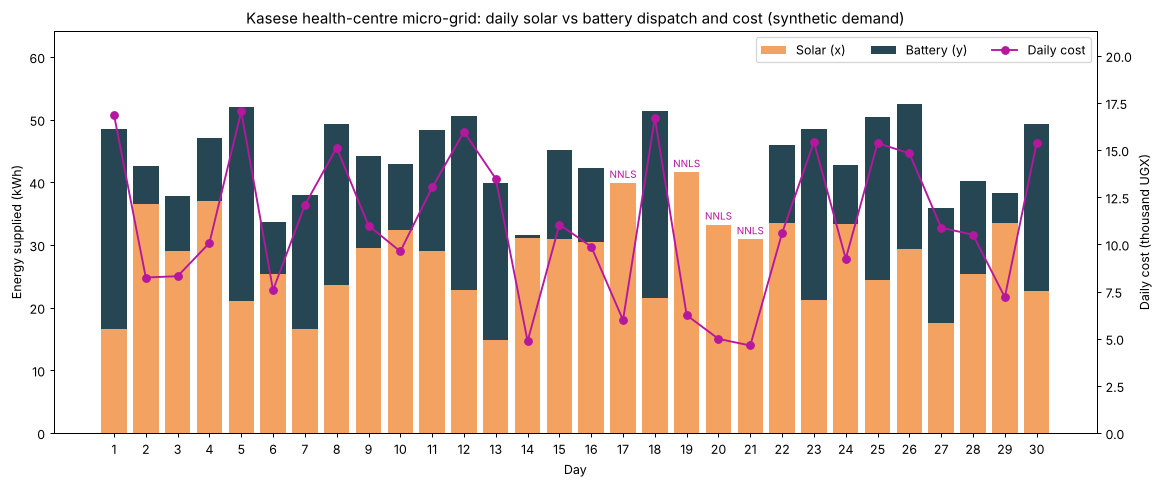

In [9]:
days = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(days, solar, color="#f4a261", label="Solar (x)")
ax.bar(days, battery, bottom=solar, color="#264653", label="Battery (y)")
for d in np.flatnonzero(result.infeasible) + 1:
    ax.annotate("NNLS", (d, solar[d - 1] + battery[d - 1]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8, color="#b5179e")
ax.set_xlabel("Day")
ax.set_ylabel("Energy supplied (kWh)")
ax.set_ylim(0, (solar + battery).max() * 1.22)
ax.set_xticks(days)
ax2 = ax.twinx()
ax2.plot(days, daily_cost / 1000, "o-", color="#b5179e", label="Daily cost")
ax2.set_ylabel("Daily cost (thousand UGX)")
ax2.set_ylim(0, daily_cost.max() / 1000 * 1.25)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", ncol=3)
ax.set_title("Kasese health-centre micro-grid: daily solar vs battery dispatch and cost (synthetic demand)")
fig.tight_layout()
fig.savefig("figures/p2_dispatch_cost.png", dpi=150)
plt.show()

Cost tracks **battery** use far more than total energy: day-to-day cost swings come almost entirely from the expensive balancing source. The infeasible (NNLS) days are cheap only because the battery was switched off and part of the critical load went unmet, which is not a saving.

## Extension A — Hybrid grid with diesel (3×3)
Third source z = diesel (UGX 1,200/kWh, illustrative), entering both loads, plus a new evening constraint x + y + z = D₃:

3x + 2y + z = D₁, 4x + y + 2z = D₂, x + y + z = D₃

In [10]:
hybrid = HybridMicroGrid()
print(hybrid, "| cond =", round(hybrid.condition_number, 2), "| rank =", hybrid.rank())
s = hybrid.solve_day(100, 110, 50)
print("Solution for D = (100, 110, 50):", s.round(2), "| check A·s =", (hybrid.A @ s).round(6))

dependent = HybridMicroGrid([[3, 2, 1], [4, 1, 2], [7, 3, 3]])   # row 3 = row 1 + row 2
print("\nDependent system: det =", round(dependent.determinant, 12), "| rank =", dependent.rank(),
      "| well-posed:", dependent.is_well_posed())
print("Consistent RHS (D3 = D1 + D2 = 210) → minimum-norm solution:", dependent.solve_day(100, 110, 210).round(2))
alt = dependent.solve_day(100, 110, 210) + 3 * np.array([3, -2, -5]) / np.linalg.norm([3, -2, -5])
print("Another exact solution (moved along the null space):", alt.round(2), "→ A·s =", (dependent.A @ alt).round(6))
print("Inconsistent RHS (D3 = 150 ≠ 210) → best compromise residual:",
      round(float(np.linalg.norm(dependent.A @ dependent.solve_day(100, 110, 150) - [100, 110, 150])), 2), "kWh")

HybridMicroGrid(sources=('solar', 'battery', 'diesel'), det=-4) | cond = 10.06 | rank = 3
Solution for D = (100, 110, 50): [15. 20. 15.] | check A·s = [100. 110.  50.]

Dependent system: det = 0.0 | rank = 2 | well-posed: False
Consistent RHS (D3 = D1 + D2 = 210) → minimum-norm solution: [20.53 16.32  5.79]
Another exact solution (moved along the null space): [21.99 15.34  3.36] → A·s = [100. 110. 210.]
Inconsistent RHS (D3 = 150 ≠ 210) → best compromise residual: 34.64 kWh


If the third equation is a **linear combination** of the others (here row 3 = row 1 + row 2), the determinant is 0 and the rank drops to 2. The third "constraint" adds no information:

* If D₃ is consistent (= D₁ + D₂) there are **infinitely many** dispatches: any point on a line, since the null space is spanned by (3, −2, −5). The solver must then add a criterion, for example cheapest or minimum-norm (what `lstsq` returns).
* If D₃ is inconsistent there is **no** exact solution, only a least-squares compromise.

Either way, `scipy.linalg.solve` would raise an error, so `HybridMicroGrid.solve_day` checks well-posedness first and falls back to `lstsq` instead of crashing. In practice, a dependent row means the third meter is measuring the same thing as the first two; the fix is a genuinely independent constraint, such as a cap on diesel hours.

## Extension B — Sensitivity analysis (Monte Carlo, ±5%, 1,000 draws)

,base (kWh),SD under ±5% demand noise (kWh),relative SD,5th pct,95th pct
solar x,28.28,1.61,0.06,25.69,30.88
battery y,14.24,3.43,0.24,8.71,19.95


Worst observed amplification ‖Δs‖/‖s‖ ÷ ‖Δd‖/‖d‖ = 5.81  (theoretical bound = cond(A) = 5.83)


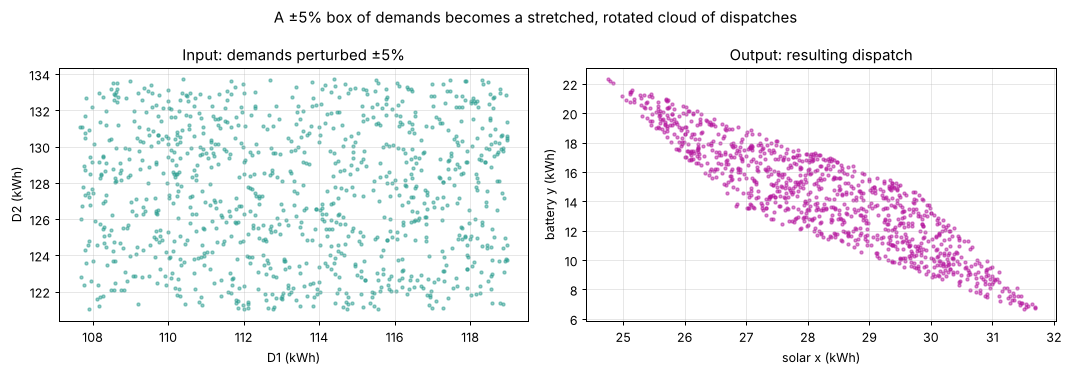

In [11]:
base = demand.mean(axis=0)
sens = sensitivity_monte_carlo(grid, base, rel_perturb=0.05, n_draws=1000, seed=SEED)
sols = sens["solutions"]
spread = pd.DataFrame({
    "base (kWh)": sens["base_solution"],
    "SD under ±5% demand noise (kWh)": sols.std(axis=0, ddof=1),
    "relative SD": sols.std(axis=0, ddof=1) / sens["base_solution"],
    "5th pct": np.percentile(sols, 5, axis=0), "95th pct": np.percentile(sols, 95, axis=0)},
    index=["solar x", "battery y"])
display(spread)
print(f"Worst observed amplification ‖Δs‖/‖s‖ ÷ ‖Δd‖/‖d‖ = {sens['max_amplification']:.2f}  "
      f"(theoretical bound = cond(A) = {sens['condition_number']:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(sens["demands"][:, 0], sens["demands"][:, 1], s=6, alpha=0.5, color="#2a9d8f")
axes[0].set(xlabel="D1 (kWh)", ylabel="D2 (kWh)", title="Input: demands perturbed ±5%")
axes[1].scatter(sols[:, 0], sols[:, 1], s=6, alpha=0.5, color="#b5179e")
axes[1].set(xlabel="solar x (kWh)", ylabel="battery y (kWh)", title="Output: resulting dispatch")
for a in axes:
    a.grid(alpha=0.3)
fig.suptitle("A ±5% box of demands becomes a stretched, rotated cloud of dispatches")
fig.tight_layout()
fig.savefig("figures/p2_sensitivity.png", dpi=150)
plt.show()

A ±5% demand perturbation moves solar by a few percent but battery by **roughly four times as much in relative terms**. The worst observed amplification sits just under the condition-number bound (≈5.8), as theory predicts: the bound is attained when the perturbation lines up with the matrix's weakest singular direction, which is almost exactly the direction that changes the battery.

## Findings & Limitations

**Findings.** The dispatch system is well-posed: the determinant is −5, so each day has one unique answer, and the condition number is about 5.8. That is safe numerically, but it still means demand errors can grow up to about six-fold in the solution. Most days are feasible, but 4 of 30 synthetic days (13%) need a negative battery value. On those days the critical load exceeds 4/3 of the daytime load, and no combination of solar and battery can meet both loads. NNLS handles them with the least possible unmet load and flags them to an operator. The battery is clearly the more volatile source (CV ≈ 0.68 against 0.25 for solar), and the Monte Carlo test shows why: it is the balancing term, so demand noise lands on it. Because battery energy costs three times as much as solar, battery volatility is also the main driver of day-to-day cost swings. Practical recommendations for the clinic are to meter the critical load accurately and to budget for battery variability rather than mean use. Recurring infeasible days point to a missing source, which the diesel extension provides.

**Limitations.** The two "constraints" are taken as given. They are energy-balance identities with fixed coefficients, not a physical model of irradiance, battery state of charge or round-trip losses. A real battery cannot discharge on day *t* what it did not charge before, and this model ignores that link between days. Demand is synthetic (seeded), so the 13% infeasible-day rate depends on the noise level I chose. Tariffs are illustrative; the marginal cost of solar is close to zero, and its true cost is capital. Finally, timings depend on the machine.